# Wheat_weather — indicateurs météo par zone de production, comparés au RONI

**Objectif** : remplacer (ou compléter) le RONI, qui mesure l'état du Pacifique et non le temps qu'il fait sur les cultures, par des **indicateurs agro-météorologiques** calculés sur les grandes zones de production de blé, puis les comparer au RONI et au prix du blé par corrélation (comme en section 4 de `Wheat_analysis.ipynb`).

**Source** : [NASA POWER](https://power.larc.nasa.gov/) (réanalyse quotidienne maillée, gratuite, sans clé) : précipitations (`PRECTOTCORR`), température maximale (`T2M_MAX`) et minimale (`T2M_MIN`) à 2 m, depuis 1981.

**Démarche**
1. Téléchargement quotidien pour quelques points représentatifs de chaque zone (cache dans `data/cache/`)
2. Contrôles de qualité
3. Agrégation mensuelle : cumul de pluie, nombre de jours de forte chaleur
4. Anomalies par rapport à la normale du mois, puis **indice de stress** (sec et chaud) limité aux **mois critiques** de chaque zone
5. Corrélations avec le prix du blé et avec le RONI, y compris décalées

> Ce notebook lit le prix du blé et le RONI dans `data/cache/` : exécuter d'abord `Wheat_analysis.ipynb`.

In [1]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
CACHE_DIR = Path("./data/cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
START, END = "19920101", "20261031"
REFRESH = False  # True : retélécharge les données NASA POWER

INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
C_WHEAT, C_RONI, C_STRESS = "#2a78d6", "#1baf7a", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 1.6, "legend.frameon": False, "figure.dpi": 100,
})

## 1. Zones de production et téléchargement

Le prix du FMI (série PWHEAMT) correspond, d'après son intitulé, au blé dur rouge d'hiver américain : les Grandes Plaines pèsent donc le plus. Les autres zones sont de grands exportateurs.

> **Hypothèses à affiner** (marquées « approximatif ») : les coordonnées sont des points représentatifs, pas des moyennes pondérées sur toute la zone ; les mois critiques sont des fenêtres agronomiques usuelles (floraison et remplissage du grain) ; les zones ont le même poids.

In [2]:
# zone -> (points (latitude, longitude), mois critiques)   -- approximatif
ZONES = {
    "US_HRW":    {"label": "Grandes Plaines (USA)", "points": [(38.5, -99.0), (36.5, -98.5), (35.2, -101.8)], "months": [3, 4, 5, 6]},
    "Russie":    {"label": "Russie du Sud",         "points": [(47.0, 40.0), (45.0, 41.5)],                  "months": [4, 5, 6, 7]},
    "France":    {"label": "France (Beauce)",       "points": [(48.2, 1.8)],                                 "months": [4, 5, 6, 7]},
    "Ukraine":   {"label": "Ukraine",               "points": [(49.0, 31.0), (47.5, 35.0)],                  "months": [4, 5, 6, 7]},
    "Canada":    {"label": "Prairies canadiennes",  "points": [(52.0, -106.5)],                              "months": [6, 7, 8]},
    "Australie": {"label": "Australie",             "points": [(-31.5, 117.5), (-34.5, 138.0)],              "months": [8, 9, 10, 11]},
}
POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"

def fetch_point(lat, lon):
    path = CACHE_DIR / f"nasa_power_{lat}_{lon}.csv"
    if path.exists() and not REFRESH:
        return pd.read_csv(path, index_col=0, parse_dates=True)
    r = requests.get(POWER_URL, params={"parameters": "PRECTOTCORR,T2M_MAX,T2M_MIN", "community": "AG",
                                        "latitude": lat, "longitude": lon, "start": START, "end": END,
                                        "format": "JSON"}, timeout=180)
    r.raise_for_status()
    frame = pd.DataFrame(r.json()["properties"]["parameter"])
    frame.index = pd.to_datetime(frame.index)
    frame = frame.replace(-999, np.nan)   # NASA POWER code les valeurs manquantes par -999
    frame.to_csv(path)
    return frame

daily = {(z, pt): fetch_point(*pt) for z, cfg in ZONES.items() for pt in cfg["points"]}
print(f"{len(daily)} points téléchargés")

11 points téléchargés


## 2. Qualité des données

In [3]:
rows = []
for (z, pt), d in daily.items():
    rows.append({"zone": z, "point": pt, "début": d.index.min().date(), "fin": d.index.max().date(),
                 "jours": len(d), "jours attendus": (d.index.max() - d.index.min()).days + 1,
                 "manquants": int(d.isna().any(axis=1).sum()),
                 "pluie max (mm/j)": d["PRECTOTCORR"].max(), "Tmax max (°C)": d["T2M_MAX"].max(),
                 "Tmin min (°C)": d["T2M_MIN"].min(), "Tmax < Tmin": int((d["T2M_MAX"] < d["T2M_MIN"]).sum())})
display(pd.DataFrame(rows).set_index(["zone", "point"]).round(1))

début         fin  jours  jours attendus  manquants  pluie max (mm/j)  Tmax max (°C)  Tmin min (°C)  Tmax < Tmin
zone      point                                                                                                                                
US_HRW    (38.5, -99.0)   1992-01-01  2026-10-31  12723           12723          0              69.9           45.1          -22.4            0
          (36.5, -98.5)   1992-01-01  2026-10-31  12723           12723          0              90.0           46.8          -20.4            0
          (35.2, -101.8)  1992-01-01  2026-10-31  12723           12723          0              56.9           44.1          -18.0            0
Russie    (47.0, 40.0)    1992-01-01  2026-10-31  12723           12723          0              38.8           42.2          -30.7            0
          (45.0, 41.5)    1992-01-01  2026-10-31  12723           12723          0             167.6           42.4          -26.4            0
France    (48.2, 1.8)     1992-01-01  2026-10-31  12723           12723          0              42.5           42.4          -12.4            0
Ukraine   (49.0, 31.0)    1992-01-01  2026-10-31  12723           12723          0              57.5           38.8          -33.3            0
          (47.5, 35.0)    1992-01-01  2026-10-31  12723           12723          0              81.0           39.3          -32.0            0
Canada    (52.0, -106.5)  1992-01-01  2026-10-31  12723           12723          0              64.9           39.4          -46.5            0
Australie (-31.5, 117.5)  1992-01-01  2026-10-31  12723           12723          0              45.2           47.1           -1.0            0
          (-34.5, 138.0)  1992-01-01  2026-10-31  12723           12723          0              64.6           39.8            4.9            0

## 3. Agrégation mensuelle et anomalies

Pour chaque point : **cumul mensuel de précipitations** et **nombre de jours à Tmax ≥ 32 °C** (stress thermique pendant la floraison). Les points d'une même zone sont moyennés. Chaque indicateur est ensuite exprimé en **anomalie centrée-réduite par mois calendaire** (par rapport à la normale du même mois sur 1992-2026) : un mois de juin sec est comparé aux autres juins, pas à décembre.

**Indice de stress d'une zone** = (sécheresse + chaleur) / 2, où sécheresse = − anomalie de pluie et chaleur = anomalie de jours chauds ; il vaut **0 hors des mois critiques**. Un stress positif signifie plus sec et plus chaud que la normale.

In [4]:
HEAT_THRESHOLD = 32.0

def monthly_point(d):
    g = d.groupby(d.index.to_period("M").to_timestamp())
    return pd.DataFrame({"precip": g["PRECTOTCORR"].sum(), "heat_days": g["T2M_MAX"].apply(lambda s: (s >= HEAT_THRESHOLD).sum())})

def calendar_z(s):
    # anomalie centrée-réduite par mois calendaire ; écart-type nul (ex. aucun jour chaud en hiver) -> 0
    z = s.groupby(s.index.month).transform(lambda x: (x - x.mean()) / x.std(ddof=0) if x.std(ddof=0) > 0 else x * 0)
    return z

zone_monthly, stress = {}, {}
for z, cfg in ZONES.items():
    pts = pd.concat([monthly_point(daily[(z, pt)]) for pt in cfg["points"]], keys=range(len(cfg["points"])))
    zm = pts.groupby(level=1).mean()
    zm["precip_z"], zm["heat_z"] = calendar_z(zm["precip"]), calendar_z(zm["heat_days"])
    in_window = zm.index.month.isin(cfg["months"])
    zm["stress"] = np.where(in_window, (-zm["precip_z"] + zm["heat_z"]) / 2, 0.0)
    zone_monthly[z], stress[z] = zm, zm["stress"]

stress = pd.DataFrame(stress)
stress["stress_global"] = stress[list(ZONES)].mean(axis=1)
print(f"Indice de stress mensuel : {stress.index.min():%Y-%m} -> {stress.index.max():%Y-%m} ({len(stress)} mois)")
display(stress.describe().round(2))

# Contrôle : dans les mois critiques, l'indice doit être centré et varier
crit = {z: stress.loc[stress.index.month.isin(ZONES[z]["months"]), z] for z in ZONES}
print("Dans les mois critiques - moyenne / écart-type :",
      {z: (round(float(v.mean()), 2), round(float(v.std()), 2)) for z, v in crit.items()})

Indice de stress mensuel : 1992-01 -> 2026-10 (418 mois)


,US_HRW,Russie,France,Ukraine,Canada,Australie,stress_global
count,418.00,418.00,418.00,418.00,418.00,418.00,418.00
mean,0.00,-0.00,0.00,0.00,-0.00,0.00,0.00
std,0.50,0.49,0.43,0.44,0.41,0.43,0.19
min,-2.00,-2.58,-1.75,-1.72,-1.60,-1.86,-0.69
25%,0.00,0.00,0.00,0.00,0.00,0.00,-0.07
50%,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,0.00,0.00,0.00,0.00,0.00,0.00,0.07
max,3.41,3.59,3.45,3.42,2.18,3.02,0.78


Dans les mois critiques - moyenne / écart-type : {'US_HRW': (0.0, 0.86), 'Russie': (-0.0, 0.86), 'France': (0.0, 0.75), 'Ukraine': (0.0, 0.76), 'Canada': (0.0, 0.82), 'Australie': (0.0, 0.74)}


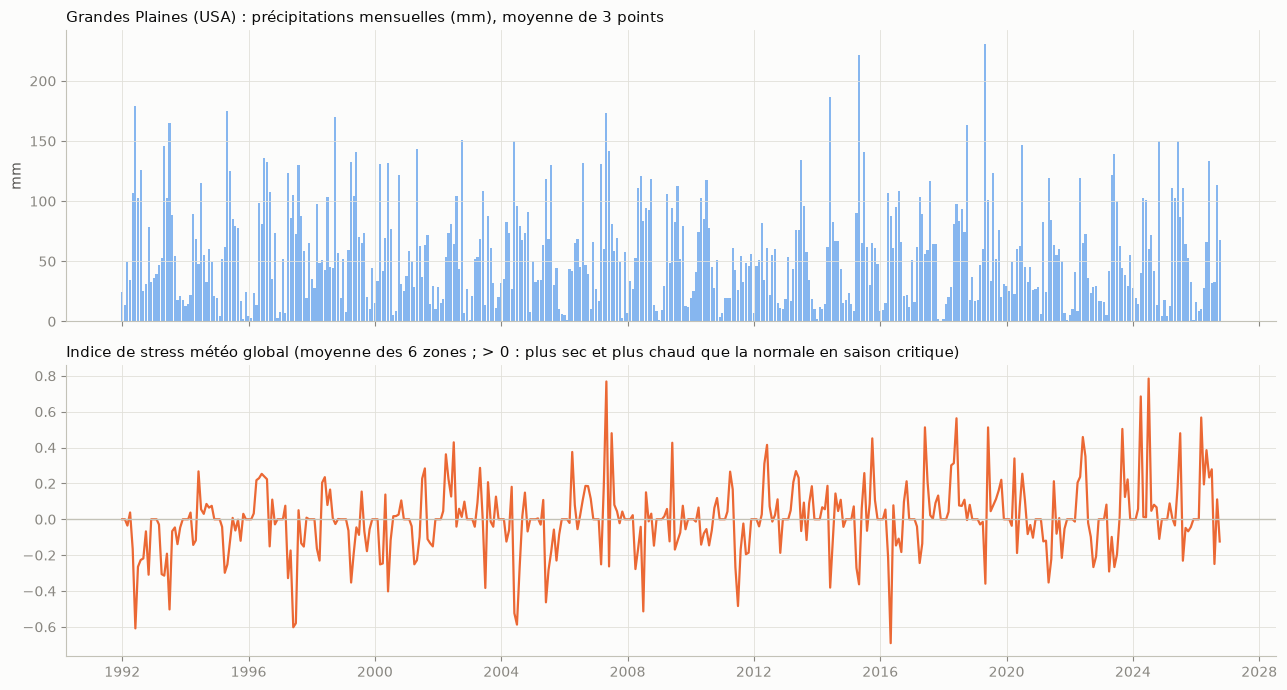

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
us = zone_monthly["US_HRW"]
axes[0].bar(us.index, us["precip"], width=25, color="#86b6ef")
axes[0].set_title("Grandes Plaines (USA) : précipitations mensuelles (mm), moyenne de 3 points"); axes[0].set_ylabel("mm")
axes[1].plot(stress.index, stress["stress_global"], color=C_STRESS)
axes[1].axhline(0, color="#c3c2b7", lw=1)
axes[1].set_title("Indice de stress météo global (moyenne des 6 zones ; > 0 : plus sec et plus chaud que la normale en saison critique)")
fig.tight_layout()
plt.show()

## 4. Comparaison avec le RONI et le prix du blé

Le prix du blé et le RONI sont lus dans le cache de `Wheat_analysis.ipynb`. Comme dans ce notebook, le blé est pris en **variation relative mensuelle (Δlog)** et le RONI en niveau.

Échantillon : 416 mois (1992-02 -> 2026-09)


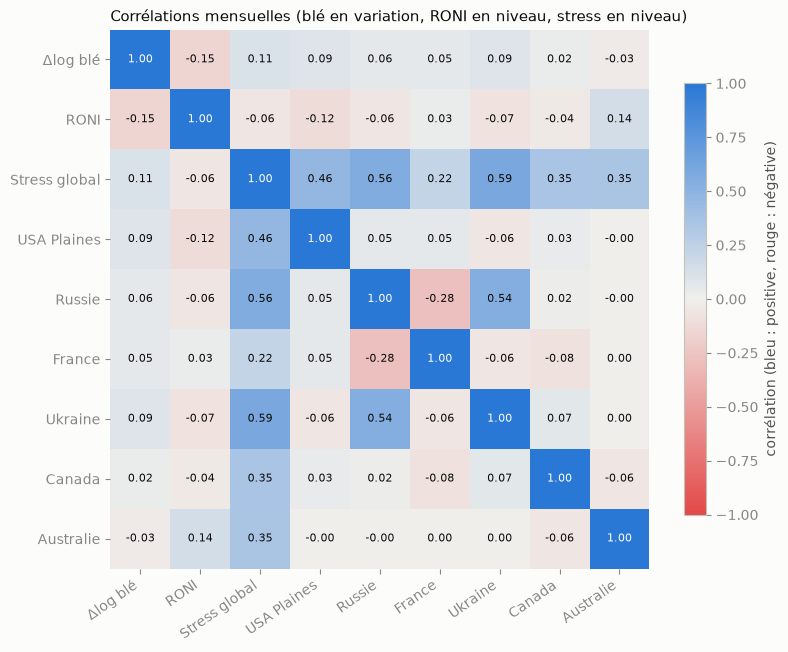

Seuil de significativité approximatif à 5 % : |r| > 0.096 (n = 416)


In [6]:
wheat = pd.read_csv(CACHE_DIR / "imf_wheat.csv", parse_dates=["date"]).set_index("date")["wheat_price_usd"]
roni = pd.read_csv(CACHE_DIR / "noaa_roni.csv", parse_dates=["date"]).set_index("date")["roni_index"]

panel = pd.concat({"r_wheat": np.log(wheat).diff(), "roni": roni, **{c: stress[c] for c in stress.columns}}, axis=1)
panel = panel.loc["1992-02":"2026-09"].dropna()
print(f"Échantillon : {len(panel)} mois ({panel.index.min():%Y-%m} -> {panel.index.max():%Y-%m})")

NAMES = {"r_wheat": "Δlog blé", "roni": "RONI", "stress_global": "Stress global", "US_HRW": "USA Plaines",
         "Russie": "Russie", "France": "France", "Ukraine": "Ukraine", "Canada": "Canada", "Australie": "Australie"}
order = list(NAMES)
corr = panel[order].corr()

DIVERGING = LinearSegmentedColormap.from_list("blue_red", ["#e34948", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), [NAMES[c] for c in order], rotation=35, ha="right")
ax.set_yticks(range(len(order)), [NAMES[c] for c in order]); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
for i in range(len(order)):
    for j in range(len(order)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="#ffffff" if abs(v) > 0.6 else INK)
fig.colorbar(im, shrink=0.8, label="corrélation (bleu : positive, rouge : négative)")
ax.set_title("Corrélations mensuelles (blé en variation, RONI en niveau, stress en niveau)")
plt.show()
n = len(panel); print(f"Seuil de significativité approximatif à 5 % : |r| > {1.96/np.sqrt(n):.3f} (n = {n})")

### Corrélations décalées avec la variation du blé
Comme en 4.3 de `Wheat_analysis.ipynb` : corrélation entre la variation du blé au mois *t* et la variable au mois *t − k* (k > 0 : la variable précède le blé). Barres colorées : au-delà du seuil de 5 %.

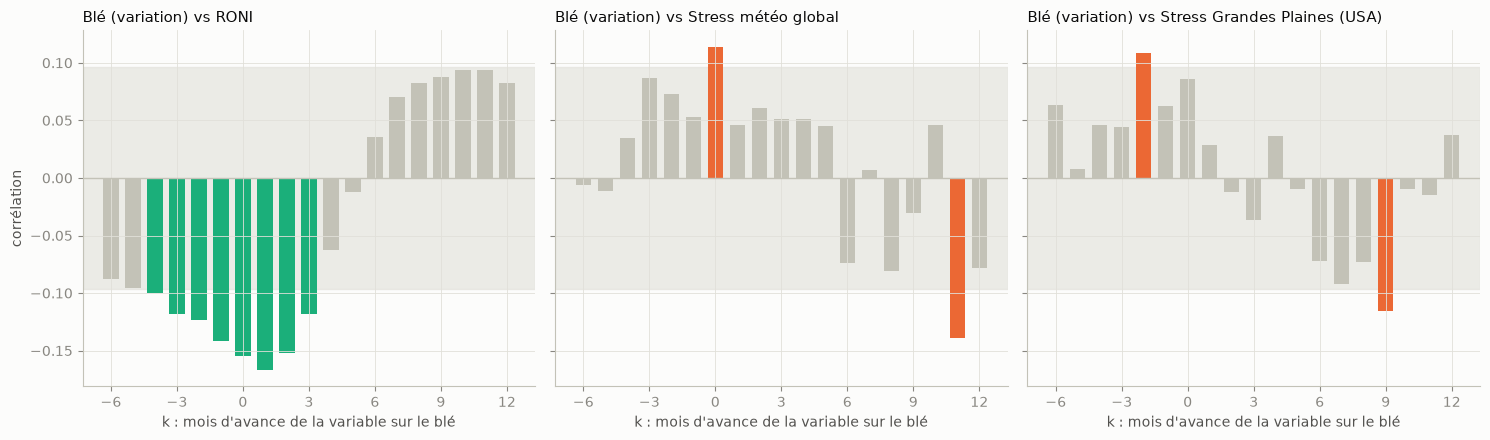

,corr à k=0,meilleur k (≥ 0),corr au meilleur k,seuil 5 %
roni,-0.155,1,-0.167,0.096
stress_global,0.114,11,-0.139,0.096
US_HRW,0.086,9,-0.116,0.096


In [7]:
LAGS = list(range(-6, 13))
band = 1.96 / np.sqrt(len(panel))
VARS = {"roni": ("RONI", C_RONI), "stress_global": ("Stress météo global", C_STRESS), "US_HRW": ("Stress Grandes Plaines (USA)", C_STRESS)}

# Les décalages utilisent les séries complètes (pas seulement l'échantillon coupé) pour ne pas perdre de mois
full = pd.concat({"r_wheat": np.log(wheat).diff(), "roni": roni, "stress_global": stress["stress_global"], "US_HRW": stress["US_HRW"]}, axis=1).loc["1992-02":"2026-09"]
lag_corr = pd.DataFrame({c: [full["r_wheat"].corr(full[c].shift(k)) for k in LAGS] for c in VARS}, index=pd.Index(LAGS, name="k"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (c, (title, color)) in zip(axes, VARS.items()):
    ax.axhspan(-band, band, color=GRID, alpha=0.6, zorder=0)
    ax.bar(LAGS, lag_corr[c], width=0.7, color=[color if abs(v) > band else "#c3c2b7" for v in lag_corr[c]])
    ax.axhline(0, color="#c3c2b7", lw=1); ax.set_title(f"Blé (variation) vs {title}")
    ax.set_xticks(range(-6, 13, 3)); ax.set_xlabel("k : mois d'avance de la variable sur le blé")
axes[0].set_ylabel("corrélation")
fig.tight_layout(); plt.show()

best = pd.DataFrame({
    "corr à k=0": lag_corr.loc[0],
    "meilleur k (≥ 0)": lag_corr.loc[lag_corr.index >= 0].abs().idxmax(),
    "corr au meilleur k": [lag_corr.loc[lag_corr.loc[lag_corr.index >= 0, c].abs().idxmax(), c] for c in lag_corr.columns],
}).round(3)
best["seuil 5 %"] = round(band, 3)
display(best)

### Stress par zone vs blé : corrélations décalées détaillées (k de 0 à 6)

In [8]:
full_z = pd.concat({"r_wheat": np.log(wheat).diff(), **{z: stress[z] for z in ZONES}}, axis=1).loc["1992-02":"2026-09"]
table = pd.DataFrame({ZONES[z]["label"]: [full_z["r_wheat"].corr(full_z[z].shift(k)) for k in range(0, 7)] for z in ZONES},
                     index=pd.Index(range(0, 7), name="k (mois)"))
display(table.round(3).style.map(lambda v: "font-weight: bold" if abs(v) > band else "").format("{:.3f}"))
print(f"En gras : |r| > {band:.3f}")

,Grandes Plaines (USA),Russie du Sud,France (Beauce),Ukraine,Prairies canadiennes,Australie
k (mois),,,,,,
0,0.086,0.057,0.050,0.094,0.024,-0.029
1,0.028,0.023,-0.002,0.099,-0.054,0.016
2,-0.012,0.019,0.017,0.092,0.051,-0.004
3,-0.037,-0.002,0.039,0.081,0.035,0.029
4,0.037,0.067,0.038,0.058,-0.043,-0.035
5,-0.009,0.057,0.007,0.042,0.047,-0.026
6,-0.072,-0.013,0.043,-0.013,-0.101,-0.022


En gras : |r| > 0.096
